In [1]:
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.datasets import mnist

# Two Layer Neural Network

In [ ]:
class TwoLayerNetBackprop:
    def __init__(
        self, input_size=28 * 28, hidden_size=100, output_size=10, weight_init_std=0.01
    ):
        self.params = {}
        self.params["w1"] = weight_init_std * np.random.randn(input_size, hidden_size)
        self.params["b1"] = np.zeros(hidden_size)
        self.params["w2"] = weight_init_std * np.random.randn(hidden_size, output_size)
        self.params["b2"] = np.zeros(output_size)

    # ReLU
    def relu(self, s):
        return np.maximum(0, s)

    # ReLU derivative
    def relu_grad(self, s):
        grad = np.zeros_like(s)
        grad[s > 0] = 1
        return grad

    # Softmax
    def softmax(self, s):
        if s.ndim == 1:
            s = s - np.max(s)
            exp_s = np.exp(s)
            return exp_s / np.sum(exp_s)

        else:
            s = s - np.max(s, axis=1, keepdims=True)
            exp_s = np.exp(s)
            return exp_s / np.sum(exp_s, axis=1, keepdims=True)

    # Prediction / Forward Propagation
    def predict(self, x):
        w1 = self.params["w1"]
        b1 = self.params["b1"]
        w2 = self.params["w2"]
        b2 = self.params["b2"]

        # Layer 1
        a1 = x @ w1 + b1
        z1 = self.relu(a1)

        # Layer 2
        a2 = z1 @ w2 + b2

        # Output
        yhat = self.softmax(a2)
        return yhat

    # Cross-Entropy Loss
    def cross_entropy_error(self, y, yhat):
        if y.ndim == 1:
            y = y.reshape(1, y.size)
            yhat = yhat.reshape(1, yhat.size)

        batch_size = y.shape[0]
        return -np.sum(y * np.log(yhat + 1e-7)) / batch_size

    # Loss
    def loss(self, x, y):
        yhat = self.predict(x)
        return self.cross_entropy_error(y, yhat)

    # Backpropagation
    def gradient(self, x, y):
        w1 = self.params["w1"]
        b1 = self.params["b1"]
        w2 = self.params["w2"]
        b2 = self.params["b2"]

        # Make sure x and y are batches
        if x.ndim == 1:
            x = x.reshape(1, -1)
        if y.ndim == 1:
            y = y.reshape(1, -1)
        batch_size = x.shape[0]

        # FORWARD PROPAGATION
        a1 = x @ w1 + b1
        z1 = self.relu(a1)

        # Hidden -> Output
        a2 = z1 @ w2 + b2
        yhat = self.softmax(a2)

        # BACKWARD PROPAGATION
        # Output layer
        # Softmax + Cross Entropy
        da2 = (yhat - y) / batch_size

        # W2 gradient
        dw2 = z1.T @ da2

        # b2 gradient
        db2 = np.sum(da2, axis=0)

        # Backpropagate to hidden layer
        dz1 = da2 @ w2.T

        # ReLU derivative
        da1 = dz1 * self.relu_grad(a1)

        # W1 gradient
        dw1 = x.T @ da1

        # b1 gradient
        db1 = np.sum(da1, axis=0)

        # Store gradients
        grad = {}
        grad["w1"] = dw1
        grad["b1"] = db1
        grad["w2"] = dw2
        grad["b2"] = db2

        return grad

# Load Data

In [3]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("Original shapes:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test :", X_test.shape)
print("y_test :", y_test.shape)

X_train = X_train.reshape(60000, 784).astype("float32") / 255.0
X_test = X_test.reshape(10000, 784).astype("float32") / 255.0

# One-hot encoding
y_train_onehot = np.eye(10)[y_train]
y_test_onehot = np.eye(10)[y_test]

Original shapes:
X_train: (60000, 28, 28)
y_train: (60000,)
X_test : (10000, 28, 28)
y_test : (10000,)


# Train

In [4]:
# Training hyperparameters
epochs = 10
learning_rate = 0.1
batch_size = 64

Training Loop

In [5]:
train_loss_list = []
train_acc_list = []

network = TwoLayerNetBackprop(input_size=28 * 28, hidden_size=100, output_size=10)

for epoch in range(epochs):
    # Shuffle training data
    indices = np.random.permutation(len(X_train))
    X_train_shuffled = X_train[indices]
    y_train_shuffled = y_train_onehot[indices]

    # Mini-batch training
    for i in range(0, len(X_train), batch_size):
        x_batch = X_train_shuffled[i : i + batch_size]
        y_batch = y_train_shuffled[i : i + batch_size]

        # Backpropagation
        grad = network.gradient(x_batch, y_batch)

        # Update weights and biases
        for key in network.params:
            network.params[key] -= learning_rate * grad[key]

    # Calculate training loss
    loss = network.loss(X_train, y_train_onehot)
    train_loss_list.append(loss)

    # Calculate training accuracy
    y_pred = network.predict(X_train)
    predicted_class = np.argmax(y_pred, axis=1)

    # y_train already contains integer labels 0-9
    true_class = y_train
    accuracy = np.mean(predicted_class == true_class)
    train_acc_list.append(accuracy)

    # Display training progress
    print(
        f"Epoch: {epoch + 1:2d}/{epochs} | Loss: {loss:.4f} | Accuracy: {accuracy:.4f}"
    )


Epoch:  1/10 | Loss: 0.2904 | Accuracy: 0.9177
Epoch:  2/10 | Loss: 0.1972 | Accuracy: 0.9441
Epoch:  3/10 | Loss: 0.1604 | Accuracy: 0.9542
Epoch:  4/10 | Loss: 0.1271 | Accuracy: 0.9646
Epoch:  5/10 | Loss: 0.1088 | Accuracy: 0.9698
Epoch:  6/10 | Loss: 0.0972 | Accuracy: 0.9728
Epoch:  7/10 | Loss: 0.0843 | Accuracy: 0.9766
Epoch:  8/10 | Loss: 0.0767 | Accuracy: 0.9783
Epoch:  9/10 | Loss: 0.0668 | Accuracy: 0.9818
Epoch: 10/10 | Loss: 0.0628 | Accuracy: 0.9830


Learning Curves

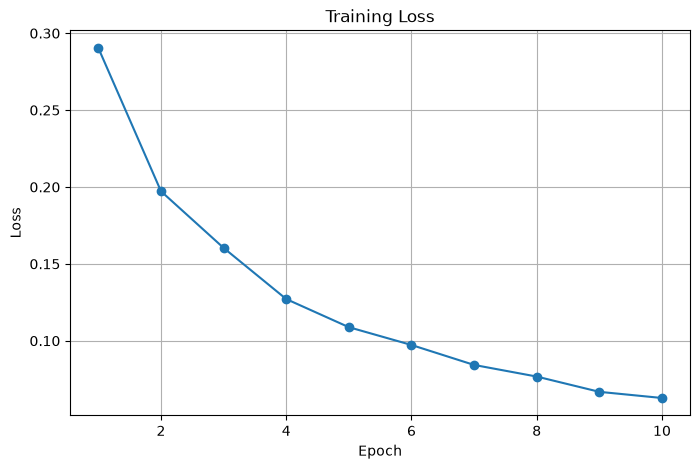

In [6]:
# plot loss vs epochs
plt.figure(figsize=(8, 5))
plt.plot(range(1, epochs + 1), train_loss_list, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.grid()
plt.show()

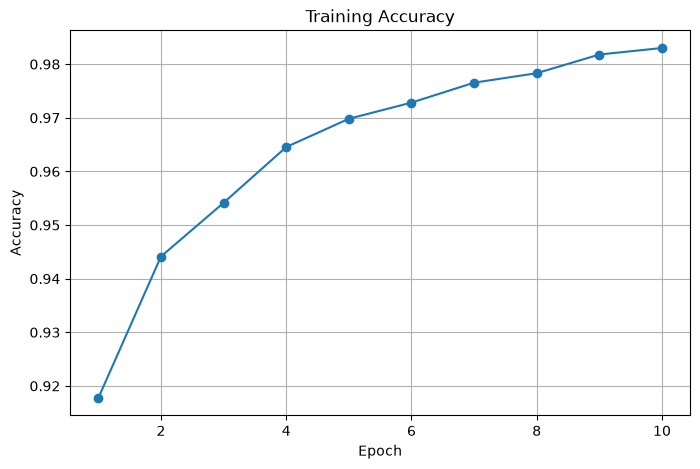

In [7]:
# plot accuracy vs epochs
plt.figure(figsize=(8, 5))
plt.plot(range(1, epochs + 1), train_acc_list, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training Accuracy")
plt.grid()
plt.show()

# Test

In [8]:
# Predict test dataset
y_test_pred = network.predict(X_test)
predicted_test_class = np.argmax(y_test_pred, axis=1)
test_accuracy = np.mean(predicted_test_class == y_test)
print(f"Test Accuracy: {test_accuracy:.4f}")

Test Accuracy: 0.9737
